In [2]:
from google.colab import files
uploaded = files.upload()

Saving processing_anemia.csv to processing_anemia.csv


In [3]:
import pandas as pd

df = pd.read_csv("processing_anemia.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (2754, 18)


,age,gender,bmi,diet_omnivore,diet_pescatarian,diet_vegan,diet_vegetarian,iron_percent_rda,vitamin_b12_percent_rda,folate_percent_rda,symptoms_count,has_fatigue,has_muscle_weakness,has_numbness_tingling,has_memory_problems,has_pale_skin,has_bone_pain,anemia_label
0,79,0,24.8,0,0,0,1,97.4,102.5,188.9,0,0,0,0,0,0,0,0
1,24,0,26.4,1,0,0,0,86.4,136.2,116.6,2,0,0,0,0,0,0,0
2,69,0,23.1,0,0,0,1,60.8,31.8,66.5,2,0,0,1,1,0,0,1
3,63,0,29.6,0,0,0,1,71.9,72.6,124.9,0,0,0,0,0,0,0,0
4,69,1,25.1,0,1,0,0,79.0,21.2,101.0,3,0,0,1,0,0,0,1


In [4]:
print(df.columns.tolist())

['age', 'gender', 'bmi', 'diet_omnivore', 'diet_pescatarian', 'diet_vegan', 'diet_vegetarian', 'iron_percent_rda', 'vitamin_b12_percent_rda', 'folate_percent_rda', 'symptoms_count', 'has_fatigue', 'has_muscle_weakness', 'has_numbness_tingling', 'has_memory_problems', 'has_pale_skin', 'has_bone_pain', 'anemia_label']


In [5]:
df["gender"] = df["gender"].map({
    "Male": 0,
    "Female": 1
})

In [6]:
print(df["gender"].unique())

[nan]


In [7]:
print(df["gender"].unique())

[nan]


In [8]:
print(df["gender"].value_counts(dropna=False))

gender
NaN    2754
Name: count, dtype: int64


In [9]:
import pandas as pd

df = pd.read_csv("processing_anemia.csv")

print(df["gender"].unique())
print(df["gender"].value_counts(dropna=False))

[0 1]
gender
0    1397
1    1357
Name: count, dtype: int64


In [10]:
print(df["gender"].unique())
print(df["gender"].value_counts())

[0 1]
gender
0    1397
1    1357
Name: count, dtype: int64


In [11]:
print(df.isnull().sum())

age                        0
gender                     0
bmi                        0
diet_omnivore              0
diet_pescatarian           0
diet_vegan                 0
diet_vegetarian            0
iron_percent_rda           0
vitamin_b12_percent_rda    0
folate_percent_rda         0
symptoms_count             0
has_fatigue                0
has_muscle_weakness        0
has_numbness_tingling      0
has_memory_problems        0
has_pale_skin              0
has_bone_pain              0
anemia_label               0
dtype: int64


In [12]:
print(df.dtypes)

age                          int64
gender                       int64
bmi                        float64
diet_omnivore                int64
diet_pescatarian             int64
diet_vegan                   int64
diet_vegetarian              int64
iron_percent_rda           float64
vitamin_b12_percent_rda    float64
folate_percent_rda         float64
symptoms_count               int64
has_fatigue                  int64
has_muscle_weakness          int64
has_numbness_tingling        int64
has_memory_problems          int64
has_pale_skin                int64
has_bone_pain                int64
anemia_label                 int64
dtype: object


In [13]:
print(df["anemia_label"].value_counts())

anemia_label
0    1509
1    1245
Name: count, dtype: int64


In [14]:
display(df.head())

,age,gender,bmi,diet_omnivore,diet_pescatarian,diet_vegan,diet_vegetarian,iron_percent_rda,vitamin_b12_percent_rda,folate_percent_rda,symptoms_count,has_fatigue,has_muscle_weakness,has_numbness_tingling,has_memory_problems,has_pale_skin,has_bone_pain,anemia_label
0,79,0,24.8,0,0,0,1,97.4,102.5,188.9,0,0,0,0,0,0,0,0
1,24,0,26.4,1,0,0,0,86.4,136.2,116.6,2,0,0,0,0,0,0,0
2,69,0,23.1,0,0,0,1,60.8,31.8,66.5,2,0,0,1,1,0,0,1
3,63,0,29.6,0,0,0,1,71.9,72.6,124.9,0,0,0,0,0,0,0,0
4,69,1,25.1,0,1,0,0,79.0,21.2,101.0,3,0,0,1,0,0,0,1


In [15]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop("anemia_label", axis=1)
y = df["anemia_label"]

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (2203, 17)
X_test : (551, 17)
y_train: (2203,)
y_test : (551,)


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaling on test data
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

X_train_scaled shape: (2203, 17)
X_test_scaled shape : (551, 17)


In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

model = Sequential([
    Dense(64, activation="relu", input_shape=(17,)),
    Dropout(0.30),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(16, activation="relu"),

    Dense(1, activation="sigmoid")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,777 (14.75 KB)

 Trainable params: 3,777 (14.75 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [19]:
print("Model compiled successfully!")

Model compiled successfully!


In [20]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [21]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8036 - loss: 0.5020 - val_accuracy: 0.9365 - val_loss: 0.2425
Epoch 2/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9438 - loss: 0.2030 - val_accuracy: 0.9569 - val_loss: 0.1184
Epoch 3/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9608 - loss: 0.1302 - val_accuracy: 0.9615 - val_loss: 0.1071
Epoch 4/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9597 - loss: 0.1142 - val_accuracy: 0.9637 - val_loss: 0.0939
Epoch 5/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9620 - loss: 0.1047 - val_accuracy: 0.9660 - val_loss: 0.0875
Epoch 6/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9682 - loss: 0.0933 - val_accuracy: 0.9660 - val_loss: 0.0855
Epoch 7/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9654 - loss: 0.0903 - val_accuracy: 0.9683 - val_loss: 0.0886
Epoch 8/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9699 - loss: 0.0926 - val_accuracy: 0.9683 - v

In [22]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9764 - loss: 0.0813 
Test Loss: 0.0812859907746315
Test Accuracy: 0.9764065146446228


In [23]:
from sklearn.metrics import classification_report

y_prob = model.predict(X_test_scaled)

y_pred = (y_prob >= 0.5).astype(int).ravel()

print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Anemia", "Anemia"]
))

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
              precision    recall  f1-score   support

  Not Anemia       0.97      0.99      0.98       302
      Anemia       0.99      0.96      0.97       249

    accuracy                           0.98       551
   macro avg       0.98      0.97      0.98       551
weighted avg       0.98      0.98      0.98       551



In [24]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob.ravel())

print("ROC-AUC:", auc)

ROC-AUC: 0.9956248836405223


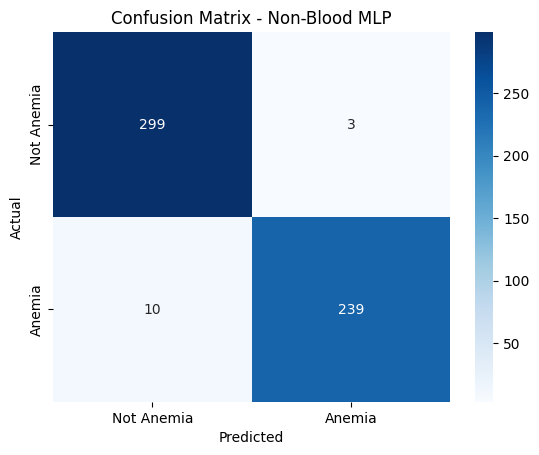

In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Anemia", "Anemia"],
    yticklabels=["Not Anemia", "Anemia"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Non-Blood MLP")
plt.show()

In [26]:

import json
import joblib
import zipfile
from pathlib import Path
from google.colab import files

# Create a folder for the exported model files
export_dir = Path("anemia_streamlit_model")
export_dir.mkdir(exist_ok=True)

# 1. Save the trained MLP model
model.save(export_dir / "anemia_mlp.keras")

# 2. Save the exact scaler fitted on the training data
joblib.dump(scaler, export_dir / "scaler.joblib")

# 3. Save the exact feature names and order used during training
feature_columns = X_train.columns.tolist()

with open(export_dir / "feature_columns.json", "w") as f:
    json.dump(feature_columns, f, indent=4)

# Package all three files together
zip_path = "anemia_streamlit_model.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in export_dir.iterdir():
        z.write(path, arcname=path.name)

print("Export completed.")
print("Features:", len(feature_columns))
print("Feature order:", feature_columns)
print("Files:", [p.name for p in export_dir.iterdir()])

# Download the package to your computer
files.download(zip_path)

Export completed.
Features: 17
Feature order: ['age', 'gender', 'bmi', 'diet_omnivore', 'diet_pescatarian', 'diet_vegan', 'diet_vegetarian', 'iron_percent_rda', 'vitamin_b12_percent_rda', 'folate_percent_rda', 'symptoms_count', 'has_fatigue', 'has_muscle_weakness', 'has_numbness_tingling', 'has_memory_problems', 'has_pale_skin', 'has_bone_pain']
Files: ['scaler.joblib', 'anemia_mlp.keras', 'feature_columns.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>